In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
incidents = pd.read_csv("../data/raw/incidents.csv")

incidents.head()

,incident_id,incident_type,latitude,longitude,reported_victims,severity,weather_condition,response_time_minutes,status,created_at
0,1,Fire,17.502241,78.387829,24,Medium,Cloudy,9,resolved,2026-07-02 04:40:15
1,2,Road Accident,17.340780,78.374722,24,Medium,Cloudy,28,resolved,2026-07-04 23:11:51
2,3,Road Accident,17.270988,78.597198,1,Low,Cloudy,46,active,2026-07-13 16:19:46
3,4,Industrial Accident,17.492652,78.388367,17,Medium,Heavy Rain,56,in_progress,2026-02-27 14:23:25
4,5,Road Accident,17.373640,78.389734,25,Medium,Rain,51,resolved,2026-06-26 03:11:44


In [3]:
incidents["created_at"] = pd.to_datetime(
    incidents["created_at"]
)

print(incidents["created_at"].dtype)

datetime64[us]


In [4]:
print("Start Date:", incidents["created_at"].min())
print("End Date:", incidents["created_at"].max())

Start Date: 2025-08-18 19:12:20
End Date: 2026-08-17 15:41:48


In [5]:
daily_demand = (
    incidents
    .set_index("created_at")
    .resample("D")
    .size()
)

daily_demand.head()

created_at
2025-08-18    1
2025-08-19    1
2025-08-20    2
2025-08-21    1
2025-08-22    1
Freq: D, dtype: int64

In [6]:
print("Number of days:", len(daily_demand))

Number of days: 365


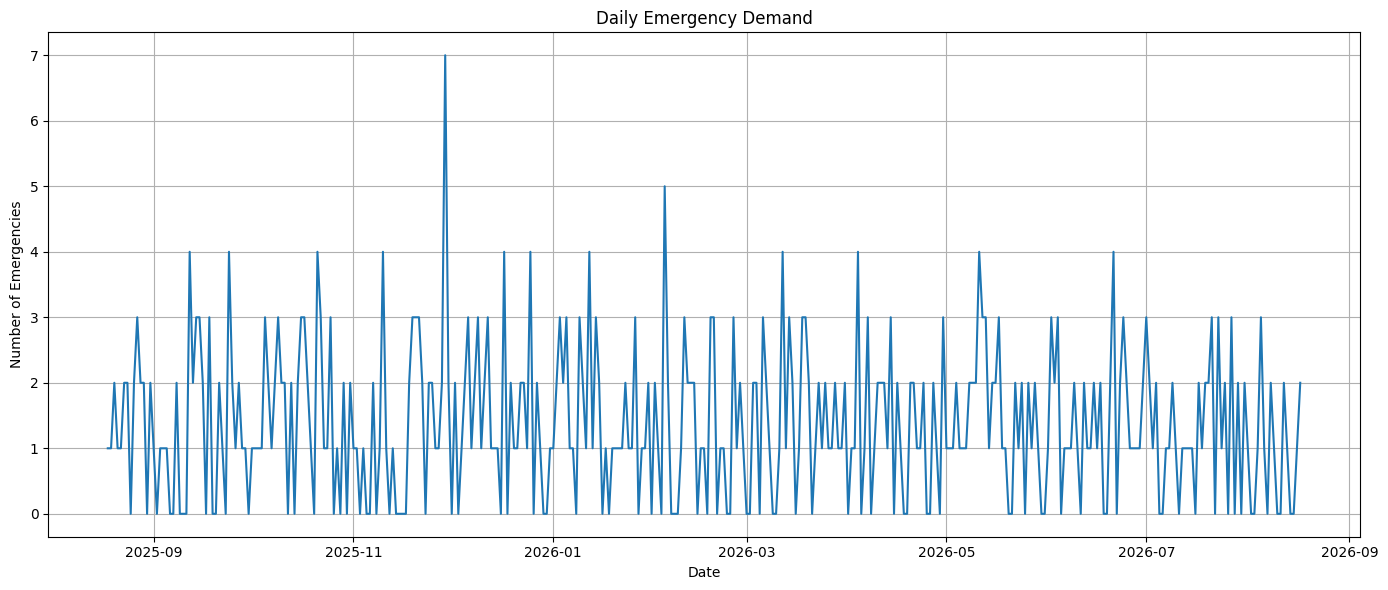

In [7]:
plt.figure(figsize=(14, 6))

plt.plot(
    daily_demand.index,
    daily_demand.values
)

plt.title("Daily Emergency Demand")
plt.xlabel("Date")
plt.ylabel("Number of Emergencies")

plt.grid(True)
plt.tight_layout()

plt.show()

In [8]:
print("Total days:", len(daily_demand))
print("Total emergencies:", daily_demand.sum())
print("Average daily demand:", round(daily_demand.mean(), 2))
print("Minimum daily demand:", daily_demand.min())
print("Maximum daily demand:", daily_demand.max())

Total days: 365
Total emergencies: 500
Average daily demand: 1.37
Minimum daily demand: 0
Maximum daily demand: 7


In [9]:
print("Missing values:", daily_demand.isna().sum())

Missing values: 0


In [10]:
print("Days with zero emergencies:", (daily_demand == 0).sum())

Days with zero emergencies: 91


In [11]:
forecast_df = daily_demand.reset_index()

forecast_df.columns = ["date", "demand"]

forecast_df["day_of_week"] = forecast_df["date"].dt.dayofweek
forecast_df["day_of_month"] = forecast_df["date"].dt.day
forecast_df["month"] = forecast_df["date"].dt.month
forecast_df["week_of_year"] = forecast_df["date"].dt.isocalendar().week.astype(int)

forecast_df.head()

,date,demand,day_of_week,day_of_month,month,week_of_year
0,2025-08-18,1,0,18,8,34
1,2025-08-19,1,1,19,8,34
2,2025-08-20,2,2,20,8,34
3,2025-08-21,1,3,21,8,34
4,2025-08-22,1,4,22,8,34


In [12]:
forecast_df["lag_1"] = forecast_df["demand"].shift(1)
forecast_df["lag_7"] = forecast_df["demand"].shift(7)

forecast_df.head(10)

,date,demand,day_of_week,day_of_month,month,week_of_year,lag_1,lag_7
0,2025-08-18,1,0,18,8,34,NaN,NaN
1,2025-08-19,1,1,19,8,34,1.0,NaN
2,2025-08-20,2,2,20,8,34,1.0,NaN
3,2025-08-21,1,3,21,8,34,2.0,NaN
4,2025-08-22,1,4,22,8,34,1.0,NaN
5,2025-08-23,2,5,23,8,34,1.0,NaN
6,2025-08-24,2,6,24,8,34,2.0,NaN
7,2025-08-25,0,0,25,8,35,2.0,1.0
8,2025-08-26,2,1,26,8,35,0.0,1.0
9,2025-08-27,3,2,27,8,35,2.0,2.0


In [13]:
forecast_df["rolling_7"] = (
    forecast_df["demand"]
    .rolling(window=7)
    .mean()
)

forecast_df.head(10)

,date,demand,day_of_week,day_of_month,month,week_of_year,lag_1,lag_7,rolling_7
0,2025-08-18,1,0,18,8,34,NaN,NaN,NaN
1,2025-08-19,1,1,19,8,34,1.0,NaN,NaN
2,2025-08-20,2,2,20,8,34,1.0,NaN,NaN
3,2025-08-21,1,3,21,8,34,2.0,NaN,NaN
4,2025-08-22,1,4,22,8,34,1.0,NaN,NaN
5,2025-08-23,2,5,23,8,34,1.0,NaN,NaN
6,2025-08-24,2,6,24,8,34,2.0,NaN,1.428571
7,2025-08-25,0,0,25,8,35,2.0,1.0,1.285714
8,2025-08-26,2,1,26,8,35,0.0,1.0,1.428571
9,2025-08-27,3,2,27,8,35,2.0,2.0,1.571429
